# Проект 1. От чего зависит удержание подписок ПРАЙМ

Подписка приносит выручку, пока действует, поэтому удержание важнее разового привлечения: каждый процент подписок, оставшихся на следующие 3 месяца, это деньги, которые не нужно зарабатывать заново. Я хочу понять, от чего удержание зависит и где его можно улучшить. Проверяю 4 фактора, которые есть в данных: шеринг (подключённые участники), тариф, канал привлечения и активность владельца в первые 14 дней

Начинаю с шеринга, потому что владелец может подключить к подписке до 5 человек, и продвигать это дешевле, чем привлекать нового клиента. Простое сравнение подписок с участниками и без них здесь ничего не доказывает, по 3 причинам. Участников подключают не в день старта, а позже, поэтому подписка, отменённая на 1-й неделе, никого позвать не успела, и шеринг выглядит полезнее, чем есть. Кроме того, шеринг может чаще встречаться там, где удержание и так лучше, например у какого-то тарифа или канала. Наконец, возможна обратная связь: клиенту нравится сервис, поэтому он зовёт близких и сам не уходит, а шеринг остаётся только признаком

Эти 3 возможности убираю по очереди. Сначала проверяю даты подключений и считаю разницу без поправок. Затем фиксирую точку отсчёта на 30-й день жизни подписки, чтобы у всех было одинаковое время позвать участников. После этого разделяю разницу на вклад состава подписок и вклад самого шеринга, сравниваю подписки с одинаковой активностью владельца в первые 14 дней и смотрю, как удержание зависит от канала. В конце перевожу разницу между каналами в рубли

Считаю по всей базе, сутки по UTC

## Зерно расчёта

Одна строка таблицы соответствует 1 подписке: у неё 1 владелец, 1 тариф и 1 канал, а вопрос про удержание задаётся именно про подписку, а не про клиента или платёж. Участников я сворачиваю до числа подключений к 30-му дню, поэтому на 1 подписку по-прежнему приходится 1 строка. Если соединить подписки с участниками напрямую, подписка с 5 участниками встретится 5 раз и её исход посчитается 5 раз, а платежи при таком соединении задвоились бы. Поэтому деньги нужны только в конце, для оценки в рублях, и там я беру средний платёж

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sqlalchemy import text

from prime.config import get_engine

engine = get_engine()


def q(sql: str, **params) -> pd.DataFrame:
    """Выполнить запрос и вернуть DataFrame. Соединение закрывается сразу."""
    try:
        with engine.connect() as conn:
            conn.execute(text("set time zone 'UTC'"))
            return pd.read_sql(text(sql), conn, params=params)
    finally:
        engine.dispose()

## Данные

In [2]:
# Подписки сразу с тарифом и каналом владельца: у клиента 1 канал, поэтому строк не прибавится
subs = q("""
    select s.subscription_id, s.owner_client_id, s.tariff_id, s.started_at, s.ended_at,
           c.acquisition_channel as channel
    from prime.subscriptions s
    join prime.clients c on c.client_id = s.owner_client_id
""")
subs["channel"] = subs["channel"].fillna("Без канала")

# Подключения участников, у каждого есть дата
members = q("""
    select subscription_id, client_id, joined_at
    from prime.subscription_members
""")

print("Подписок:", len(subs), " Уникальных:", subs["subscription_id"].is_unique)
print("Подключений участников:", len(members))
print("Самое позднее оформление подписки:", subs["started_at"].max())
print("Самое позднее подключение участника:", members["joined_at"].max())

Подписок: 333905  Уникальных: True
Подключений участников: 555858
Самое позднее оформление подписки: 2026-08-29 23:35:55+00:00
Самое позднее подключение участника: 2026-10-27 20:30:50+00:00


Подписки оформляли до 29.08, а последнее подключение участника датировано 27.10, то есть позже самой поздней подписки. Прежде чем опираться на эти даты, проверяю связи между таблицами

In [3]:
m = members.merge(subs[["subscription_id", "owner_client_id", "started_at", "ended_at"]],
                  on="subscription_id", how="left", validate="m:1")

print("Подключений к подписке, которой нет в таблице подписок:", int(m["started_at"].isna().sum()))
print("Подключений, где участник это сам владелец:", int((m["client_id"] == m["owner_client_id"]).sum()))
print("Подключений раньше старта подписки:", int((m["joined_at"] < m["started_at"]).sum()))
print("Подключений позже последнего оформления подписки:", int((m["joined_at"] > subs["started_at"].max()).sum()))

Подключений к подписке, которой нет в таблице подписок: 0
Подключений, где участник это сам владелец: 1
Подключений раньше старта подписки: 0
Подключений позже последнего оформления подписки: 17332


Подключений позже последнего оформления подписки 17 332. На расчёт они не влияют: в анализ войдут подписки, оформленные не позже 23.07, и у них первые 30 дней заканчиваются не позже 22.08. Владельца из списка участников убираю, потому что свою подписку он не делит

In [4]:
m = m[(m["client_id"] != m["owner_client_id"]) & m["started_at"].notna()].copy()
m["days_to_join"] = (m["joined_at"] - m["started_at"]).dt.total_seconds() / 86400

per_sub = m.groupby("subscription_id").size()

print("Доля подписок хотя бы с 1 участником:", round(100 * len(per_sub) / len(subs), 1), "%")
print("\nУчастников на подписку (только подписки с шерингом):")
print(per_sub.value_counts().sort_index().to_string())

Доля подписок хотя бы с 1 участником: 70.0 %

Участников на подписку (только подписки с шерингом):
1    65983
2    66354
3    66111
4    17592
5    17693


In [5]:
print("Через сколько дней после старта подключают (квантили):")
print(m["days_to_join"].quantile([0.25, 0.5, 0.75, 0.9]).round(0).astype(int).to_string())
print("\nПодключили в первые 30 дней:", round(100 * (m["days_to_join"] <= 30).mean(), 1), "%")

Через сколько дней после старта подключают (квантили):
0.25    15
0.50    30
0.75    45
0.90    53

Подключили в первые 30 дней: 51.7 %


Подписок с 4 и 5 участниками заметно меньше, чем с 1, 2 или 3, а подключают людей в основном в первые недели после старта. Это пригодится дальше, когда нужно будет выбрать точку отсчёта

In [6]:
# Ищу дни с аномальным числом отмен
per_day = subs.loc[subs["ended_at"].notna(), "ended_at"].dt.normalize().value_counts().sort_index()

print("Обычное число отмен в день (медиана):", int(per_day.median()))
print("\nДни с наибольшим числом отмен:")
print(per_day.nlargest(3).to_string())

Обычное число отмен в день (медиана): 162

Дни с наибольшим числом отмен:
ended_at
2026-08-23 00:00:00+00:00    14215
2026-08-22 00:00:00+00:00    13967
2026-08-17 00:00:00+00:00      277


22 и 23 августа отменено по 14 тыс. подписок при обычных 162 в день. Такой скачок похож на массовое закрытие, а не на решения отдельных клиентов, и к удержанию он отношения не имеет. Если оставить эти дни, подписки, действовавшие в конце августа, будут выглядеть так, будто их удержание рухнуло, поэтому наблюдение заканчиваю в начале 22.08

In [7]:
cut = per_day.nlargest(2).index.min()

print("Граница наблюдения:", cut.date())

Граница наблюдения: 2026-08-22


## Сравнение без поправок

Сначала считаю разницу без каких-либо поправок. Беру подписки, которым исполнилось 120 дней к границе наблюдения, и смотрю долю действующих подписок на 120-й день отдельно для подписок, у которых когда-либо были участники, и для остальных

In [8]:
old = subs[subs["started_at"] + pd.Timedelta(days=120) <= cut].copy()
old["has_members"] = old["subscription_id"].isin(per_sub.index)
old["alive_120"] = old["ended_at"].isna() | (old["ended_at"] > old["started_at"] + pd.Timedelta(days=120))

naive = old.groupby("has_members")["alive_120"].agg(["size", "mean"])
naive["mean"] = (100 * naive["mean"]).round(1)
naive.index = naive.index.map({True: "С участниками", False: "Без участников"})
naive.columns = ["Подписок", "Действуют через 120 дней, %"]

naive_gap = naive.loc["С участниками", "Действуют через 120 дней, %"] - naive.loc["Без участников", "Действуют через 120 дней, %"]

print(naive.to_string())
print("\nРазница без поправок, п.п.:", round(naive_gap, 1))

                Подписок  Действуют через 120 дней, %
has_members                                          
Без участников     86293                         84.4
С участниками     201345                         84.4

Разница без поправок, п.п.: 0.0


Разница равна 0, а я ожидала обратного. Подписка, отменённая в 1-й месяц, почти не успевает собрать участников, поэтому группа с участниками должна была выглядеть лучше. Проверяю, так ли это: сравниваю долю подписок с участниками среди отменённых в первые 30 дней и среди остальных

In [9]:
died_early = old["ended_at"].notna() & (old["ended_at"] <= old["started_at"] + pd.Timedelta(days=30))

print("Доля подписок с участниками среди отменённых в первые 30 дней:", round(100 * old.loc[died_early, "has_members"].mean(), 1), "%")
print("Доля подписок с участниками среди действующих на 30-й день:", round(100 * old.loc[~died_early, "has_members"].mean(), 1), "%")

Доля подписок с участниками среди отменённых в первые 30 дней: 69.3 %
Доля подписок с участниками среди действующих на 30-й день: 70.0 %


## Точка отсчёта

Для честного сравнения нужна точка, в которой у всех подписок было одинаковое время позвать участников, группа уже известна, а исход нет. Беру 30-й день жизни подписки, он совпадает с концом 1-го платёжного цикла. В анализ входят только подписки, дожившие до этого дня. Делю их на тех, у кого к этому дню был участник, и тех, у кого не было, и считаю долю действующих ещё через 90 дней, то есть после 3 следующих платежей

In [10]:
LANDMARK, HORIZON = 30, 90

first_join_all = m.groupby("subscription_id")["days_to_join"].min()


def landmark_frame(landmark):
    """Строка таблицы соответствует подписке, действующей на день landmark. shared: был ли участник к этому дню."""
    d = subs[["subscription_id", "tariff_id", "channel", "started_at", "ended_at"]].copy()
    d["land"] = d["started_at"] + pd.Timedelta(days=landmark)
    d = d[(d["land"] <= cut) & (d["ended_at"].isna() | (d["ended_at"] > d["land"]))].copy()

    # Подключение было к точке отсчёта, если с момента старта прошло не больше landmark дней
    early = m.loc[m["days_to_join"] <= landmark, "subscription_id"]
    d["n_members"] = d["subscription_id"].map(early.value_counts()).fillna(0).astype(int)
    first = d["subscription_id"].map(first_join_all)
    d["first_join"] = first.where(first <= landmark)
    d["shared"] = d["n_members"] > 0
    return d


def retained(d, days):
    """Подписки, которых мы наблюдаем ещё days дней после точки отсчёта, и действует ли каждая из них."""
    t = d["land"] + pd.Timedelta(days=days)
    seen = d[t <= cut].copy()
    seen["kept"] = (seen["ended_at"].isna() | (seen["ended_at"] > t[seen.index])).astype(int)
    return seen


base = landmark_frame(LANDMARK)
x = retained(base, HORIZON)

print("Действующих на 30-й день:", len(base), " Из них наблюдаем ещё 90 дней:", len(x))

Действующих на 30-й день: 306804  Из них наблюдаем ещё 90 дней: 275468


In [11]:
sizes = x.groupby("shared")["kept"].agg(["size", "mean"])
p1, p0 = sizes.loc[True, "mean"], sizes.loc[False, "mean"]
n1, n0 = sizes.loc[True, "size"], sizes.loc[False, "size"]

# Разница долей и 95 % интервал вокруг неё: 1,96 стандартных ошибок
landmark_gap = 100 * (p1 - p0)
se = 100 * (p1 * (1 - p1) / n1 + p0 * (1 - p0) / n0) ** 0.5
gap_low, gap_high = landmark_gap - 1.96 * se, landmark_gap + 1.96 * se

landmark = pd.DataFrame({"Подписок": [n1, n0], "Действуют ещё через 90 дней, %": [100 * p1, 100 * p0]},
                        index=["С участниками к 30-му дню", "Без участников к 30-му дню"])

print(landmark.round(1).to_string())
print("\nРазница после фиксации точки отсчёта, п.п.:", round(landmark_gap, 2))
print("95 % интервал, п.п.: от", round(gap_low, 2), "до", round(gap_high, 2))

                            Подписок  Действуют ещё через 90 дней, %
С участниками к 30-му дню     146431                            88.1
Без участников к 30-му дню    129037                            88.2

Разница после фиксации точки отсчёта, п.п.: -0.12
95 % интервал, п.п.: от -0.36 до 0.13


Через 90 дней действуют 88,1 % подписок с участниками и 88,2 % без них. Разница равна −0,12 п.п., а 95 %-ный интервал от −0,36 до 0,13 включает 0, поэтому отличия от 0 нет. Чтобы результат не зависел от выбранных чисел 30 и 90, пересчитываю его при других точках отсчёта и горизонтах

In [12]:
rows = []
for land, hor in [(14, 60), (30, 60), (30, 90), (30, 180), (60, 90)]:
    xx = retained(landmark_frame(land), hor)
    rate = xx.groupby("shared")["kept"].mean() * 100
    rows.append({"Точка отсчёта, дней": land, "Горизонт, дней": hor, "Подписок": len(xx),
                 "С участниками, %": rate[True], "Без участников, %": rate[False],
                 "Разница, п.п.": rate[True] - rate[False]})

sensitivity = pd.DataFrame(rows).set_index(["Точка отсчёта, дней", "Горизонт, дней"])

print(sensitivity.round(1).to_string())

                                    Подписок  С участниками, %  Без участников, %  Разница, п.п.
Точка отсчёта, дней Горизонт, дней                                                              
14                  60                304166              91.7               91.8           -0.1
30                  60                285766              91.8               91.9           -0.1
                    90                275468              88.1               88.2           -0.1
                    180               244269              77.7               77.9           -0.2
60                  90                254090              88.2               88.3           -0.1


При всех сочетаниях разница лежит между −0,2 и −0,1 п.п., выбор 30 и 90 на результат не влияет

## Тариф и канал

Средняя разница, равная 0, может скрывать эффекты разного знака: у какого-то тарифа или канала шеринг помогает, у другого вредит. Поэтому смотрю на долю шеринга и удержание отдельно по тарифам и каналам

In [13]:
by_tariff = x.groupby(["tariff_id", "shared"])["kept"].agg(["size", "mean"]).unstack("shared")
by_tariff.columns = ["Подписок без шеринга", "Подписок с шерингом", "Действуют без шеринга, %", "Действуют с шерингом, %"]
by_tariff["Доля шеринга, %"] = 100 * by_tariff["Подписок с шерингом"] / (by_tariff["Подписок с шерингом"] + by_tariff["Подписок без шеринга"])
by_tariff[["Действуют без шеринга, %", "Действуют с шерингом, %"]] *= 100

print(by_tariff.round(1).to_string())

           Подписок без шеринга  Подписок с шерингом  Действуют без шеринга, %  Действуют с шерингом, %  Доля шеринга, %
tariff_id                                                                                                               
1                         84780                86472                      88.1                     88.1             50.5
2                         44257                59959                      88.4                     88.1             57.5


In [14]:
by_channel = x.groupby(["channel", "shared"])["kept"].agg(["size", "mean"]).unstack("shared")
by_channel.columns = ["Подписок без шеринга", "Подписок с шерингом", "Действуют без шеринга, %", "Действуют с шерингом, %"]
by_channel["Доля шеринга, %"] = 100 * by_channel["Подписок с шерингом"] / (by_channel["Подписок с шерингом"] + by_channel["Подписок без шеринга"])
by_channel[["Действуют без шеринга, %", "Действуют с шерингом, %"]] *= 100

print(by_channel.round(1).to_string())

                 Подписок без шеринга  Подписок с шерингом  Действуют без шеринга, %  Действуют с шерингом, %  Доля шеринга, %
channel                                                                                                                       
crm                             15118                17432                      90.1                     90.2             53.6
organic                         31131                35328                      93.7                     93.3             53.2
partner_telecom                 22782                25812                      88.6                     88.1             53.1
performance                     27616                30989                      84.6                     84.7             52.9
referral                        10291                11538                      92.0                     91.9             52.9
social                          19509                22366                      80.4                     80.6  

Доля шеринга по тарифам 50 и 58 %, по каналам около 53 % везде. Внутри тарифов и каналов удержание с шерингом и без него почти совпадает, различия не больше нескольких десятых процентного пункта

Чтобы не оценивать это на глаз, разделяю разницу между группами на 2 части. Состав возникает из-за того, что в группе с шерингом иначе распределены сегменты «тариф × канал». Ставка возникает внутри того же сегмента. Вместе они дают разницу точно

In [15]:
def mix_rate(a, b, min_n=30):
    """Разница средних долей b − a: состав (другие веса сегментов) и ставка (другие доли внутри сегмента).
    a и b: таблицы с колонками n (сколько) и kept (сколько осталось), индекс это сегмент."""
    common = a.index[a["n"] >= min_n].intersection(b.index[b["n"] >= min_n])
    covered = (a.loc[common, "n"].sum() + b.loc[common, "n"].sum()) / (a["n"].sum() + b["n"].sum())
    a, b = a.loc[common], b.loc[common]

    wa, wb = a["n"] / a["n"].sum(), b["n"] / b["n"].sum()
    ra, rb = a["kept"] / a["n"], b["kept"] / b["n"]

    total = (wb * rb).sum() - (wa * ra).sum()
    mix = ((wb - wa) * ra).sum()
    rate = (wb * (rb - ra)).sum()
    assert abs(mix + rate - total) < 1e-9, "Слагаемые не дают разницу"
    return {"total": total, "mix": mix, "rate": rate, "segments": len(common), "covered": covered}


x["segment"] = x["tariff_id"].astype(str) + " / " + x["channel"]
seg = x.groupby(["shared", "segment"])["kept"].agg(n="size", kept="sum")

adj = mix_rate(seg.loc[False], seg.loc[True])

print("Сегментов в расчёте:", adj["segments"], " Покрыто подписок:", round(100 * adj["covered"]), "%")
print("Разница между группами, п.п.:", round(100 * adj["total"], 1))
print("  из них состав, п.п.:       ", round(100 * adj["mix"], 1))
print("  из них сам шеринг, п.п.:   ", round(100 * adj["rate"], 1))

Сегментов в расчёте: 14  Покрыто подписок: 100 %
Разница между группами, п.п.: -0.1
  из них состав, п.п.:        0.0
  из них сам шеринг, п.п.:    -0.1


Состав даёт 0,0 п.п., а разница в −0,1 п.п. целиком приходится на ставку и остаётся такой же малой. Значит, различия по тарифам и каналам тоже ничего не объясняют, и первые 2 возможности из начала проекта отпали

## Активность владельца

Остаётся 3-я возможность: довольный клиент и приглашает близких, и сам остаётся. Полностью исключить её без эксперимента нельзя, но можно проверить, связан ли шеринг с активностью владельца. Для этого считаю его сессии в первые 14 дней подписки и делю подписки на 4 группы одинакового размера. Если вовлечённые владельцы приглашают чаще, доля шеринга вырастет от группы к группе. Активность беру за 14 дней, а не за 30, чтобы она шла раньше подключений участников

In [16]:
# Сессии владельца в первые 14 дней. Беру подписки только 2026 года, чтобы запрос не был слишком тяжёлым
FIRST = pd.Timestamp("2026-01-01", tz="UTC")
LAST = cut - pd.Timedelta(days=LANDMARK + HORIZON)

usage14 = q("""
    select s.subscription_id, count(u.client_id) as sessions_14
    from prime.subscriptions s
    left join prime.service_usage u
      on u.client_id = s.owner_client_id
     and u.started_at >= s.started_at
     and u.started_at <  s.started_at + interval '14 days'
     and u.started_at >= cast(:first as timestamptz)
     and u.started_at <  cast(:last as timestamptz) + interval '14 days'
    where s.started_at >= :first and s.started_at < :last
    group by s.subscription_id
""", first=FIRST, last=LAST)

print("Подписок с активностью:", len(usage14), " Уникальных:", usage14["subscription_id"].is_unique)

Подписок с активностью: 40991  Уникальных: True


In [17]:
xe = x[(x["started_at"] >= FIRST) & (x["started_at"] < LAST)].merge(usage14, on="subscription_id", how="left", validate="1:1")
xe["sessions_14"] = xe["sessions_14"].fillna(0)

# 4 группы одинакового размера. rank нужен, чтобы одинаковые значения не склеили группы
xe["activity"] = pd.qcut(xe["sessions_14"].rank(method="first"), 4, labels=[1, 2, 3, 4]).astype(int)

by_activity = xe.groupby(["activity", "shared"])["kept"].agg(["size", "mean"]).unstack("shared")
by_activity.columns = ["Подписок без шеринга", "Подписок с шерингом", "Действуют без шеринга, %", "Действуют с шерингом, %"]
by_activity["Доля шеринга, %"] = 100 * by_activity["Подписок с шерингом"] / (by_activity["Подписок с шерингом"] + by_activity["Подписок без шеринга"])
by_activity[["Действуют без шеринга, %", "Действуют с шерингом, %"]] *= 100

print("Группа 1 самая тихая, группа 4 самая активная")
print(by_activity.round(1).to_string())

Группа 1 самая тихая, группа 4 самая активная
          Подписок без шеринга  Подписок с шерингом  Действуют без шеринга, %  Действуют с шерингом, %  Доля шеринга, %
activity                                                                                                               
1                         4688                 5132                      88.0                     88.5             52.3
2                         4623                 5197                      88.5                     88.1             52.9
3                         4669                 5150                      88.2                     88.5             52.4
4                         4588                 5232                      88.1                     88.7             53.3


In [18]:
xe["segment"] = xe["tariff_id"].astype(str) + " / " + xe["channel"]
xe["segment_act"] = xe["segment"] + " / активность " + xe["activity"].astype(str)

seg_a = xe.groupby(["shared", "segment"])["kept"].agg(n="size", kept="sum")
seg_b = xe.groupby(["shared", "segment_act"])["kept"].agg(n="size", kept="sum")

before = mix_rate(seg_a.loc[False], seg_a.loc[True])
adj_act = mix_rate(seg_b.loc[False], seg_b.loc[True])

print("Подписок в выборке:", len(xe))
print("Разница между группами, п.п.:", round(100 * before["total"], 1))
print("  сам шеринг после поправки на тариф и канал, п.п.:", round(100 * before["rate"], 1))
print("  сам шеринг после поправки ещё и на активность, п.п.:", round(100 * adj_act["rate"], 1))

Подписок в выборке: 39279
Разница между группами, п.п.: 0.3
  сам шеринг после поправки на тариф и канал, п.п.: 0.2
  сам шеринг после поправки ещё и на активность, п.п.: 0.3


Доля шеринга во всех 4 группах 52–53 %: активные владельцы приглашают не чаще тихих, поэтому общей причины, которая толкала бы и к шерингу, и к удержанию одновременно, по этому признаку не видно. После поправки на тариф, канал и активность разница между группами равна 0,3 п.п. На выборке в 39 тыс. подписок стандартная ошибка такой разницы около 0,3 п.п., так что она неотличима от 0

Ограничение в том, что сессии за 14 дней измеряют вовлечённость грубо. Если она определяется чем-то, чего в данных нет, я её не увидела

## Число участников и срок подключения

Если шеринг всё-таки действует, он должен действовать сильнее при большем числе участников и, возможно, при раннем подключении. Средняя разница, равная 0, не исключает эффекта у части подписок, поэтому проверяю оба признака отдельно

In [19]:
x["members_group"] = x["n_members"].clip(upper=3).map({0: "0", 1: "1", 2: "2", 3: "3 и больше"})
dose = x.groupby("members_group")["kept"].agg(["size", "mean"]).reindex(["0", "1", "2", "3 и больше"])
dose["mean"] = (100 * dose["mean"]).round(1)
dose.columns = ["Подписок", "Действуют ещё через 90 дней, %"]

print(dose.to_string())

               Подписок  Действуют ещё через 90 дней, %
members_group                                          
0                129037                            88.2
1                 80484                            88.0
2                 45763                            88.1
3 и больше        20184                            88.1


In [20]:
# Тех, кто подключил участника, делю по срокам: в 1-ю неделю или позже
timing = np.select([~x["shared"], x["first_join"] <= 7], ["Без участников", "1-я неделя"], "С 8-го по 30-й день")
speed = x.groupby(timing)["kept"].agg(["size", "mean"]).reindex(["Без участников", "1-я неделя", "С 8-го по 30-й день"])
speed["mean"] = (100 * speed["mean"]).round(1)
speed.columns = ["Подписок", "Действуют ещё через 90 дней, %"]

print(speed.to_string())

                     Подписок  Действуют ещё через 90 дней, %
Без участников         129037                            88.2
1-я неделя              53798                            88.2
С 8-го по 30-й день     92633                            88.0


Удержание не зависит ни от числа участников (88,2 % без них, 88,0–88,1 % с 1, 2, 3 и больше участниками), ни от срока подключения (88,2 % при подключении в 1-ю неделю и 88,0 % позже)

## Изменение со временем

Если бы доля шеринга росла со временем, удержание новых подписок могло бы меняться только из-за этого. Для проверки сравниваю подписки 1-го полугодия 2025 года и 2026 года и разделяю изменение удержания тем же способом на состав (изменилась доля шеринга и тарифов) и ставку (изменилось удержание внутри групп)

In [21]:
older = x[(x["started_at"] >= "2025-01-01") & (x["started_at"] < "2025-07-01")]
newer = x[x["started_at"] >= "2026-01-01"]

seg_time_a = older.groupby(["tariff_id", "shared"])["kept"].agg(n="size", kept="sum")
seg_time_b = newer.groupby(["tariff_id", "shared"])["kept"].agg(n="size", kept="sum")

over_time = mix_rate(seg_time_a, seg_time_b)

print("Подписок: старшие", len(older), " новые", len(newer))
print("Доля с шерингом, %: старшие", round(100 * older["shared"].mean(), 1), " новые", round(100 * newer["shared"].mean(), 1))
print("Действуют ещё через 90 дней, %: старшие", round(100 * older["kept"].mean(), 1), " новые", round(100 * newer["kept"].mean(), 1))
print("\nИзменение удержания, п.п.:", round(100 * over_time["total"], 1))
print("  из них рост доли шеринга и тарифов, п.п.:", round(100 * over_time["mix"], 1))
print("  из них изменение внутри групп, п.п.:    ", round(100 * over_time["rate"], 1))

Подписок: старшие 62904  новые 39279
Доля с шерингом, %: старшие 53.2  новые 52.7
Действуют ещё через 90 дней, %: старшие 87.9  новые 88.3

Изменение удержания, п.п.: 0.4
  из них рост доли шеринга и тарифов, п.п.: 0.0
  из них изменение внутри групп, п.п.:     0.4


Доля шеринга почти не менялась (53,2 и 52,7 %), а удержание выросло с 87,9 до 88,3 %. Состав объясняет в этом росте 0,0 п.п., всё остальное произошло внутри групп, поэтому шеринг это изменение не объясняет

## Каналы

Шеринг, тариф и активность удержание не меняют, но в таблице по каналам видно, что сами каналы отличаются друг от друга сильно. Смотрю на это отдельно: считаю долю действующих через 90 дней по каналу для всех подписок вместе и добавляю 95 %-ный интервал, чтобы видеть, какие различия выходят за пределы случайного разброса

In [22]:
overall = 100 * x["kept"].mean()

by_ch = x.groupby("channel")["kept"].agg(["size", "mean"])
by_ch.columns = ["Подписок", "Действуют ещё через 90 дней, %"]
by_ch["±, п.п."] = 196 * (by_ch["Действуют ещё через 90 дней, %"] / 100 * (1 - by_ch["Действуют ещё через 90 дней, %"] / 100) / by_ch["Подписок"]) ** 0.5
by_ch["Действуют ещё через 90 дней, %"] *= 100
by_ch = by_ch.sort_values("Действуют ещё через 90 дней, %")

print("Всего по всем каналам:", round(overall, 1), "%")
print(by_ch.round(1).to_string())

Всего по всем каналам: 88.1 %
                 Подписок  Действуют ещё через 90 дней, %  ±, п.п.
channel                                                           
social              41875                            80.5      0.1
performance         58605                            84.6      0.1
partner_telecom     48594                            88.3      0.1
Без канала           5556                            88.9      0.2
crm                 32550                            90.2      0.1
referral            21829                            91.9      0.1
organic             66459                            93.5      0.1


Удержание сильно зависит от канала привлечения: у social действуют около 80 % подписок, у organic около 93 %. Разрыв между крайними каналами около 13 п.п., а интервалы крайних каналов далеко друг от друга, тогда как самое большое различие, которое дал шеринг, не превышает 0,3 п.п. Раз канал единственный фактор с заметным эффектом, остаётся посмотреть, сколько это стоит

## Оценка в рублях

Беру 2 канала с самым низким удержанием и считаю, сколько подписок дополнительно действовало бы через 90 дней, если бы они удерживались на уровне остальных каналов. Расчёт идёт по подпискам, начавшимся за последний год, и показывает верхнюю границу: он предполагает, что качество подписок канала можно изменить, а по наблюдательным данным этого не проверить. В рубли перевожу через средний платёж

In [23]:
avg_check = float(q("""
    select avg(amount) as avg_check
    from prime.payments
    where status = 'success' and paid_at >= '2026-06-01' and paid_at < '2026-08-22'
""").iloc[0, 0])

rate_ch = x.groupby("channel")["kept"].mean()
weak = rate_ch.nsmallest(2).index
reference = x.loc[~x["channel"].isin(weak), "kept"].mean()

last_year = base[(base["started_at"] >= cut - pd.Timedelta(days=365)) & base["channel"].isin(weak)]
n_weak = last_year["channel"].value_counts()
extra = n_weak * (reference - rate_ch[weak])

print("Слабые каналы:", ", ".join(weak), " Удержание остальных каналов:", round(100 * reference, 1), "%")
print("Средний платёж:", round(avg_check), "₽")
print("\nПодписок на 30-й день за последний год и добавка, если подтянуть удержание до уровня остальных:")
print(pd.DataFrame({"Подписок": n_weak, "Разрыв, п.п.": 100 * (reference - rate_ch[weak]), "Добавка подписок": extra}).round(1).to_string())
print("\nВсего добавка:", round(extra.sum()), "подписок, ", f"{extra.sum() * avg_check:,.0f}".replace(",", " "), "₽ в месяц")

Слабые каналы: social, performance  Удержание остальных каналов: 91.1 %
Средний платёж: 325 ₽

Подписок на 30-й день за последний год и добавка, если подтянуть удержание до уровня остальных:
             Подписок  Разрыв, п.п.  Добавка подписок
channel                                              
performance     24907           6.5            1612.5
social          17646          10.6            1869.4

Всего добавка: 3482 подписок,  1 131 197 ₽ в месяц


## Графики

In [24]:
def pct(x, digits=0):
    return f"{100 * x:+.{digits}f}".replace("-", "−")


ACCENT, GRAY = "#C1272D", "#9CA3AF"

sns.set_theme(style="whitegrid", rc={"figure.dpi": 110, "grid.color": "#E5E7EB"})

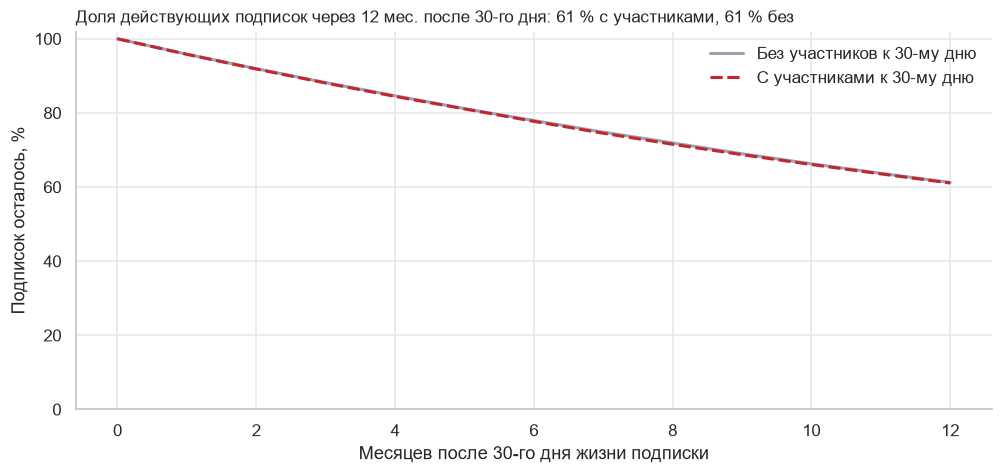

In [25]:
# График 1: сколько подписок остаётся со временем после 30-го дня
rows = []
for k in range(0, 13):
    xx = retained(base, 30 * k)
    rate = xx.groupby("shared")["kept"].agg(["size", "mean"])
    if len(rate) == 2 and rate["size"].min() >= 300:
        rows.append({"month": k, "Без участников к 30-му дню": 100 * rate.loc[False, "mean"],
                     "С участниками к 30-му дню": 100 * rate.loc[True, "mean"]})
curve = pd.DataFrame(rows).set_index("month")
curve_long = curve.reset_index().melt(id_vars="month", var_name="Группа", value_name="alive")
last = curve.index.max()
title1 = f"Доля действующих подписок через {last} мес. после 30-го дня: {curve.iloc[-1, 1]:.0f} % с участниками, {curve.iloc[-1, 0]:.0f} % без"

fig, ax = plt.subplots(figsize=(9, 4.2), layout="constrained")
sns.lineplot(data=curve_long, x="month", y="alive", hue="Группа", style="Группа",
             palette={"Без участников к 30-му дню": GRAY, "С участниками к 30-му дню": ACCENT},
             linewidth=2, ax=ax)
ax.set_ylim(bottom=0)
ax.set_xlabel("Месяцев после 30-го дня жизни подписки")
ax.set_ylabel("Подписок осталось, %")
ax.legend(title=None, frameon=False)
ax.set_title(title1, loc="left", fontsize=11)
sns.despine()
plt.show()

Линии подписок с участниками и без них совпадают на всём протяжении 12 месяцев: через год остаётся около 61 % и тех, и других. Шеринг не меняет форму кривой, а не только значение через 90 дней

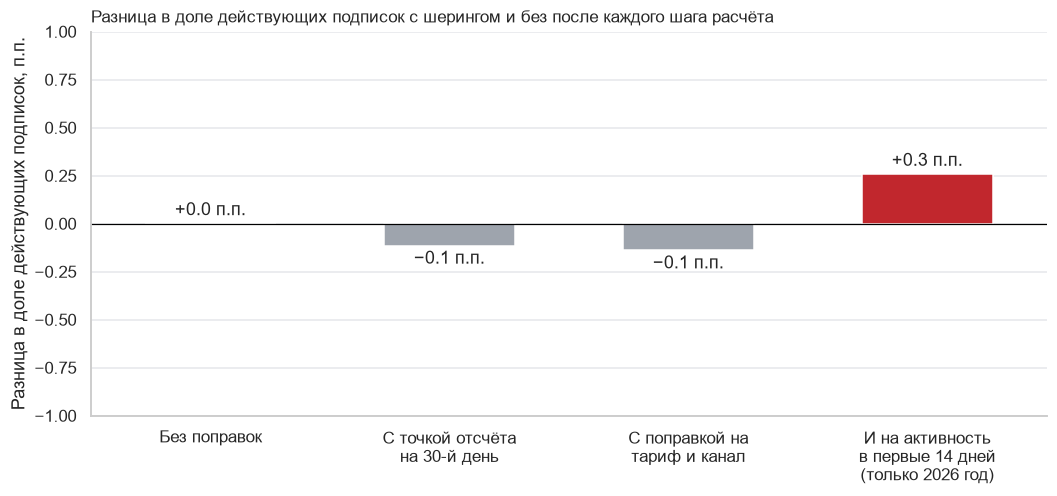

In [26]:
# График 2: разница между подписками с шерингом и без после каждого шага
steps = pd.DataFrame({"step": ["Без поправок", "С точкой отсчёта\nна 30-й день", "С поправкой на\nтариф и канал", "И на активность\nв первые 14 дней\n(только 2026 год)"],
                      "gap": [naive_gap, landmark_gap, 100 * adj["rate"], 100 * adj_act["rate"]]})
title2 = "Разница в доле действующих подписок с шерингом и без после каждого шага расчёта"

fig, ax = plt.subplots(figsize=(9.5, 4.4), layout="constrained")
sns.barplot(data=steps, x="step", y="gap", color=GRAY, width=0.55, ax=ax)
ax.patches[-1].set_facecolor(ACCENT)
ax.bar_label(ax.containers[0], labels=[f"{pct(v / 100, 1)} п.п." for v in steps["gap"]], padding=3)
ax.axhline(0, color="black", linewidth=0.8)
lim = max(1, 1.3 * steps["gap"].abs().max())  # шкала не меньше ±1 п.п., чтобы малые различия не выглядели большими
ax.set_ylim(-lim, lim)
ax.set_xlabel("")
ax.set_ylabel("Разница в доле действующих подписок, п.п.")
ax.set_title(title2, loc="left", fontsize=11)
sns.despine()
plt.show()

Разница между группами не превышает 0,3 п.п. ни на одном шаге, и ни одна поправка не делает её заметной. Последний столбец посчитан только по подпискам 2026 года, поэтому он не продолжает предыдущие напрямую, но тоже лежит около 0

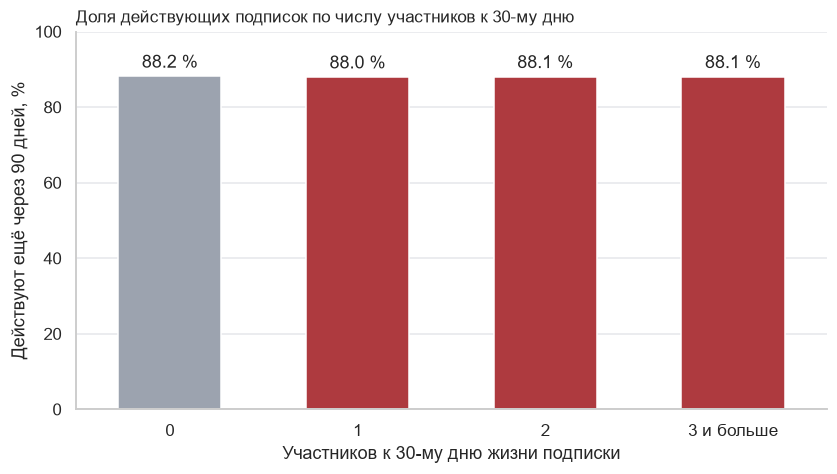

In [27]:
# График 3: удержание по числу участников
dose_plot = dose.reset_index()
vals = dose_plot["Действуют ещё через 90 дней, %"]
title3 = "Доля действующих подписок по числу участников к 30-му дню"

fig, ax = plt.subplots(figsize=(7.5, 4.2), layout="constrained")
sns.barplot(data=dose_plot, x="members_group", y="Действуют ещё через 90 дней, %", color=ACCENT, width=0.55, ax=ax)
ax.patches[0].set_facecolor(GRAY)
ax.bar_label(ax.containers[0], labels=[f"{v:.1f} %" for v in vals], padding=3)
ax.set_ylim(0, 100)
ax.set_xlabel("Участников к 30-му дню жизни подписки")
ax.set_ylabel("Действуют ещё через 90 дней, %")
ax.set_title(title3, loc="left", fontsize=11)
sns.despine()
plt.show()

Доля действующих подписок через 90 дней держится на уровне 88,0–88,2 % при любом числе участников, поэтому зависимости от числа подключённых людей нет

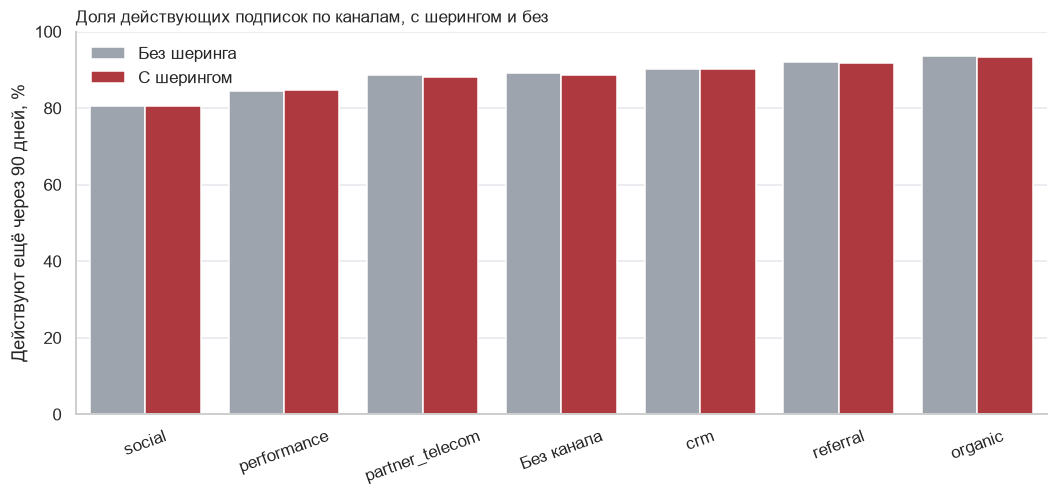

In [28]:
# График 4: удержание по каналам с шерингом и без
ch = by_channel[["Действуют без шеринга, %", "Действуют с шерингом, %"]].sort_values("Действуют без шеринга, %")
ch_long = ch.reset_index().melt(id_vars="channel", var_name="Группа", value_name="alive")
ch_long["Группа"] = ch_long["Группа"].map({"Действуют без шеринга, %": "Без шеринга", "Действуют с шерингом, %": "С шерингом"})
title4 = "Доля действующих подписок по каналам, с шерингом и без"

fig, ax = plt.subplots(figsize=(9.5, 4.4), layout="constrained")
sns.barplot(data=ch_long, x="channel", y="alive", hue="Группа", order=ch.index,
            palette={"Без шеринга": GRAY, "С шерингом": ACCENT}, ax=ax)
ax.tick_params(axis="x", rotation=20)
ax.set_xlabel("")
ax.set_ylim(0, 100)
ax.set_ylabel("Действуют ещё через 90 дней, %")
ax.legend(title=None, frameon=False)
ax.set_title(title4, loc="left", fontsize=11)
sns.despine()
plt.show()

Внутри каждого канала столбцы с шерингом и без него почти одинаковы, а между каналами разница большая: от около 80 % у social до около 93 % у organic. Так видно, что удержание определяется каналом, а не шерингом

## Выводы

Из 4 проверенных факторов удержание объясняет только канал привлечения. Через 90 дней после 30-го дня действуют 88,1 % подписок с участниками и 88,2 % без них, и эта разница не появляется ни при других точках отсчёта и горизонтах, ни внутри тарифов, каналов и групп по активности владельца, ни при разном числе участников, ни при раннем подключении. Тариф тоже ничего не меняет, активность владельца за 14 дней не связана ни с шерингом, ни с удержанием. Каналы же различаются сильно: у social действуют около 80 % подписок, у organic около 93 %

На этих данных продвигать шеринг как способ удержания не нужно. Усилия лучше направить на каналы с самым низким удержанием: либо менять качество привлекаемых подписок, либо сравнить стоимость привлечения с тем, сколько денег эти каналы теряют на оттоке. Если подтянуть social и performance до удержания остальных каналов (91,1 %), через 90 дней действовали бы ещё около 3,5 тыс. подписок, это около 1,1 млн ₽ в месяц. Это верхняя граница, потому что расчёт предполагает, что качество канала можно изменить. Если шеринг всё же остаётся интересным, его стоит проверить экспериментом: показывать подсказку «пригласите близких» случайным 50 % владельцев и сравнивать удержание, потому что по наблюдениям причину от следствия не отделить

Ограничения: около 48 % участников подключается позже 30-го дня, поэтому в группу «без участников» попадают и те, кто пригласит близких позже. Это сдвигает разницу к 0, но при точке отсчёта в 60 дней результат тот же. Различие каналов тоже наблюдательное: возможно, оно отражает состав клиентов, а не качество канала. Влияние шеринга на другие показатели, например на использование сервиса, я не проверяла. Закрытие 22–23.08 в расчёт не входит, граница наблюдения стоит на 22.08